# DTAF1-Topo on the real perturbation sample

`real_data_evaluation.ipynb` found DTAF1's road-breakage blind spot on real SpaceNet tiles
(75% road dropout leaves `dtaf1` at 1.000), but it predates `dtaf1_topo`, the connectivity-aware
fix, which had only been validated on the synthetic `sweep_road_breakage()`. This notebook re-runs
the same road/building perturbation families on the same Vegas + Khartoum sample with
`evaluate_all()`, which now also returns `dtaf1_topo` and per-class APLS, so every number in the
paper's real-data case studies (§10.2) comes from one run.

It is a separate notebook rather than a re-execution of `real_data_evaluation.ipynb` so that
notebook's recorded Potsdam point results stay intact (re-running it needs a Kaggle token).
Results are written to the tracked `results/real_data/`. Run `spacenet_data_prep.ipynb` first
(only the Vegas and Khartoum caches are read).

In [1]:
import sys, os, time
sys.path.insert(0, os.path.abspath(".."))

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import shift as nd_shift, binary_erosion, binary_dilation

from metrics import evaluate_all

ROOT = Path("..").resolve()
DATA_DIR = ROOT / "data"
OUT_DIR = ROOT / "results" / "real_data"
OUT_DIR.mkdir(parents=True, exist_ok=True)
CITIES = ["Vegas", "Khartoum"]

tiles = []
for city in CITIES:
    for p in sorted((DATA_DIR / "spacenet" / city).glob("*.npz")):
        tiles.append({"city": city, "tile": p.stem, "label": np.load(p)["label"]})
print(f"Loaded {len(tiles)} SpaceNet tiles across {CITIES}")
for city in CITIES:
    names = [t["tile"] for t in tiles if t["city"] == city]
    print(f"  {city} ({len(names)}): {', '.join(names)}")

Loaded 50 SpaceNet tiles across ['Vegas', 'Khartoum']
  Vegas (25): Vegas_img1066, Vegas_img1150, Vegas_img1154, Vegas_img1155, Vegas_img1206, Vegas_img1262, Vegas_img1370, Vegas_img1458, Vegas_img1557, Vegas_img189, Vegas_img36, Vegas_img416, Vegas_img47, Vegas_img51, Vegas_img535, Vegas_img622, Vegas_img720, Vegas_img809, Vegas_img820, Vegas_img825, Vegas_img842, Vegas_img900, Vegas_img902, Vegas_img923, Vegas_img986
  Khartoum (25): Khartoum_img125, Khartoum_img183, Khartoum_img189, Khartoum_img199, Khartoum_img203, Khartoum_img228, Khartoum_img240, Khartoum_img248, Khartoum_img256, Khartoum_img259, Khartoum_img276, Khartoum_img299, Khartoum_img32, Khartoum_img325, Khartoum_img334, Khartoum_img337, Khartoum_img366, Khartoum_img416, Khartoum_img447, Khartoum_img451, Khartoum_img454, Khartoum_img456, Khartoum_img50, Khartoum_img6, Khartoum_img8


## Perturbations

Copied unchanged from `real_data_evaluation.ipynb` (same functions, severities, iteration order
and `default_rng(0)`), so the perturbed predictions match that notebook's for the same tiles.

In [2]:
def perturb_offset(label, cls, offset_px, axis=1):
    out = label.copy()
    cls_mask = (label == cls)
    shifted = nd_shift(cls_mask.astype(np.uint8), shift=[offset_px if a == axis else 0 for a in range(2)],
                        order=0, mode="constant", cval=0)
    out[cls_mask] = 0
    out[shifted > 0] = cls
    return out


def perturb_erode(label, cls, iterations):
    out = label.copy()
    cls_mask = (label == cls)
    eroded = binary_erosion(cls_mask, iterations=iterations) if iterations > 0 else cls_mask
    out[cls_mask] = 0
    out[eroded] = cls
    return out


def perturb_dilate(label, cls, iterations):
    out = label.copy()
    cls_mask = (label == cls)
    dilated = binary_dilation(cls_mask, iterations=iterations) if iterations > 0 else cls_mask
    dilated = dilated & (label != (3 - cls) if cls in (1, 2) else True)
    out[dilated] = cls
    return out


def perturb_dropout(label, cls, fraction, rng):
    out = label.copy()
    idx = np.argwhere(label == cls)
    if len(idx) == 0 or fraction <= 0:
        return out
    n_remove = int(fraction * len(idx))
    if n_remove == 0:
        return out
    drop = idx[rng.choice(len(idx), n_remove, replace=False)]
    out[drop[:, 0], drop[:, 1]] = 0
    return out


rng = np.random.default_rng(0)
PERTURBATIONS = {
    "road_offset":     lambda gt, sev: perturb_offset(gt, cls=1, offset_px=sev),
    "road_dropout":    lambda gt, sev: perturb_dropout(gt, cls=1, fraction=sev, rng=rng),
    "road_thicken":    lambda gt, sev: perturb_dilate(gt, cls=1, iterations=sev),
    "building_erode":  lambda gt, sev: perturb_erode(gt, cls=2, iterations=sev),
}
SEVERITIES = {
    "road_offset":    [0, 4, 8, 12, 16],
    "road_dropout":   [0.0, 0.25, 0.5, 0.75],
    "road_thicken":   [0, 2, 4, 6],
    "building_erode": [0, 1, 2, 3],
}

## Evaluate

In [3]:
rows = []
t0 = time.time()
for i, t in enumerate(tiles):
    gt = t["label"]
    for pert_name, pert_fn in PERTURBATIONS.items():
        for sev in SEVERITIES[pert_name]:
            pred = pert_fn(gt, sev)
            r = evaluate_all(pred, gt, linear_classes=[1], polygon_classes=[2])
            apls_road = r["per_class_detail"]["apls"].get(1, {})
            rows.append({
                "city": t["city"], "tile": t["tile"],
                "road_px": int((gt == 1).sum()), "building_px": int((gt == 2).sum()),
                "perturbation": pert_name, "severity": sev,
                "cbhm": r["cbhm"], "cbhm_soft": r["cbhm_soft"],
                "dtaf1": r["dtaf1"], "dtaf1_weighted": r["dtaf1_weighted"],
                "dtaf1_topo": r["dtaf1_topo"], "dtaf1_topo_weighted": r["dtaf1_topo_weighted"],
                "road_apls": apls_road.get("apls", np.nan),
                "cldice_mean": r["cldice_mean"], "bf_mean": r["bf_mean"],
            })
    print(f"  {i + 1}/{len(tiles)} tiles, {time.time() - t0:.0f}s", flush=True)

results = pd.DataFrame(rows)
results.to_csv(OUT_DIR / "perturbation_results.csv", index=False)
print(f"{len(results)} rows -> {OUT_DIR / 'perturbation_results.csv'}")

  1/50 tiles, 40s


  2/50 tiles, 80s


  3/50 tiles, 132s


  4/50 tiles, 200s


  5/50 tiles, 250s


  6/50 tiles, 306s


... (41 outputs left out)

  48/50 tiles, 2534s


  49/50 tiles, 2553s


  50/50 tiles, 2577s


850 rows -> C:\Users\danzg\PycharmProjects\PLEM\results\real_data\perturbation_results.csv


## Road breakage: does `dtaf1_topo` close DTAF1's blind spot on real data?

In [4]:
COLS = ["dtaf1", "dtaf1_weighted", "dtaf1_topo", "road_apls", "cldice_mean", "cbhm", "cbhm_soft"]
pd.set_option("display.precision", 3)
dropout = results[results.perturbation == "road_dropout"].groupby("severity")[COLS].mean()
dropout

,dtaf1,dtaf1_weighted,dtaf1_topo,road_apls,cldice_mean,cbhm,cbhm_soft
severity,,,,,,,
0.00,1.0,1.0,1.000,1.000,1.000,1.000,1.000
0.25,1.0,1.0,0.987,0.950,0.857,0.923,0.930
0.50,1.0,1.0,0.622,0.147,0.666,0.799,0.837
0.75,1.0,1.0,0.501,0.001,0.400,0.572,0.707


In [5]:
results[results.perturbation == "road_dropout"].groupby("severity")[COLS].std()

,dtaf1,dtaf1_weighted,dtaf1_topo,road_apls,cldice_mean,cbhm,cbhm_soft
severity,,,,,,,
0.00,0.0,0.0,0.000,0.000,0.000,0.000,0.000
0.25,0.0,0.0,0.006,0.021,0.004,0.002,0.026
0.50,0.0,0.0,0.075,0.106,0.005,0.004,0.063
0.75,0.0,0.0,0.004,0.004,0.008,0.008,0.112


## Road offset (APLS is snap-tolerant, so `dtaf1_topo` should degrade gracefully here)

In [6]:
results[results.perturbation == "road_offset"].groupby("severity")[COLS].mean()

,dtaf1,dtaf1_weighted,dtaf1_topo,road_apls,cldice_mean,cbhm,cbhm_soft
severity,,,,,,,
0.0,1.000,1.000,1.000,1.000,1.000,1.000,1.000
4.0,1.000,1.000,0.998,0.991,0.998,0.999,0.999
8.0,1.000,1.000,0.996,0.984,0.940,0.967,0.967
12.0,0.983,0.984,0.792,0.445,0.632,0.767,0.819
16.0,0.944,0.946,0.747,0.361,0.572,0.720,0.787


## Every family, all metrics (means)

In [7]:
summary = results.groupby(["perturbation", "severity"])[COLS + ["bf_mean"]].mean()
summary.to_csv(OUT_DIR / "perturbation_summary.csv")
summary

dtaf1  dtaf1_weighted  dtaf1_topo  road_apls  \
perturbation   severity                                                 
building_erode 0.00      1.000           1.000       1.000      1.000   
               1.00      1.000           1.000       1.000      1.000   
               2.00      0.998           0.998       0.998      1.000   
               3.00      0.978           0.979       0.978      1.000   
road_dropout   0.00      1.000           1.000       1.000      1.000   
               0.25      1.000           1.000       0.987      0.950   
               0.50      1.000           1.000       0.622      0.147   
               0.75      1.000           1.000       0.501      0.001   
road_offset    0.00      1.000           1.000       1.000      1.000   
               4.00      1.000           1.000       0.998      0.991   
               8.00      1.000           1.000       0.996      0.984   
               12.00     0.983           0.984       0.792      0.445   
               16.00     0.944           0.946       0.747      0.361   
road_thicken   0.00      1.000           1.000       1.000      1.000   
               2.00      1.000           1.000       0.999      0.994   
               4.00      1.000           1.000       0.996      0.987   
               6.00      1.000           1.000       0.992      0.971   

                         cldice_mean   cbhm  cbhm_soft  bf_mean  
perturbation   severity                                          
building_erode 0.00            1.000  1.000      1.000    1.000  
               1.00            1.000  1.000      1.000    1.000  
               2.00            1.000  0.998      0.998    0.995  
               3.00            1.000  0.979      0.981    0.960  
road_dropout   0.00            1.000  1.000      1.000    1.000  
               0.25            0.857  0.923      0.930    1.000  
               0.50            0.666  0.799      0.837    1.000  
               0.75            0.400  0.572      0.707    1.000  
road_offset    0.00            1.000  1.000      1.000    1.000  
               4.00            0.998  0.999      0.999    1.000  
               8.00            0.940  0.967      0.967    1.000  
               12.00           0.632  0.767      0.819    0.999  
               16.00           0.572  0.720      0.787    0.998  
road_thicken   0.00            1.000  1.000      1.000    1.000  
               2.00            0.999  0.999      0.999    1.000  
               4.00            0.996  0.998      0.998    1.000  
               6.00            0.992  0.996      0.996    1.000

## Sparse-class collapse cases (paper §5.2 / §10.2 Finding 2)

`Khartoum_img371` and `Khartoum_img333` come from the original, smaller sample and are not in the
re-drawn one, so they are cached separately under `data/spacenet_cases/` with the current
(exact-index) building labels and scored under the same road offsets. They are not part of the
aggregates above.

In [8]:
case_cols = ["tile", "perturbation", "severity", "road_px", "building_px",
             "cbhm", "cbhm_soft", "dtaf1", "dtaf1_topo", "road_apls", "cldice_mean", "bf_mean"]
case_rows = []
for p in sorted((DATA_DIR / "spacenet_cases" / "Khartoum").glob("*.npz")):
    d = np.load(p)
    gt = d["label"]
    print(f"{p.stem}: road px {(gt == 1).sum()}, building px {(gt == 2).sum()}, "
          f"road share {(gt == 1).mean():.4%}, building labels known on {d['building_valid'].mean():.2f}")
    for sev in SEVERITIES["road_offset"]:
        r = evaluate_all(perturb_offset(gt, cls=1, offset_px=sev), gt,
                         linear_classes=[1], polygon_classes=[2])
        case_rows.append({"tile": p.stem, "perturbation": "road_offset", "severity": sev,
                          "road_px": int((gt == 1).sum()), "building_px": int((gt == 2).sum()),
                          "road_apls": r["per_class_detail"]["apls"].get(1, {}).get("apls", np.nan),
                          **{k: r[k] for k in ["cbhm", "cbhm_soft", "dtaf1", "dtaf1_topo",
                                               "cldice_mean", "bf_mean"]}})
cases = pd.DataFrame(case_rows)
cases.to_csv(OUT_DIR / "case_tiles_road_offset.csv", index=False)
display(cases[case_cols])

# The tiles where cbhm collapses to exactly 0 under a road offset while dtaf1 stays high
collapse = results[(results.perturbation == "road_offset") & (results.severity > 0)
                   & (results.cbhm == 0) & (results.dtaf1 > 0.8)]
collapse[case_cols].sort_values(["tile", "severity"])

Khartoum_img333: road px 11879, building px 66461, road share 0.7029%, building labels known on 0.50


Khartoum_img371: road px 1052, building px 1529, road share 0.0622%, building labels known on 0.50


,tile,perturbation,severity,road_px,building_px,cbhm,cbhm_soft,dtaf1,dtaf1_topo,road_apls,cldice_mean,bf_mean
0,Khartoum_img333,road_offset,0,11879,66461,1.000,1.000,1.000,1.000,1.000,1.000,1.0
1,Khartoum_img333,road_offset,4,11879,66461,0.998,0.999,1.000,0.992,0.968,0.996,1.0
2,Khartoum_img333,road_offset,8,11879,66461,0.517,0.901,1.000,0.981,0.927,0.348,1.0
3,Khartoum_img333,road_offset,12,11879,66461,0.480,0.896,0.948,0.711,0.276,0.316,1.0
4,Khartoum_img333,road_offset,16,11879,66461,0.446,0.892,0.832,0.630,0.162,0.287,1.0
5,Khartoum_img371,road_offset,0,1052,1529,1.000,1.000,1.000,1.000,1.000,1.000,1.0
6,Khartoum_img371,road_offset,4,1052,1529,0.958,0.967,1.000,0.975,0.905,0.920,1.0
7,Khartoum_img371,road_offset,8,1052,1529,0.490,0.725,1.000,0.964,0.866,0.325,1.0
8,Khartoum_img371,road_offset,12,1052,1529,0.000,0.592,0.934,0.500,0.000,0.000,1.0
9,Khartoum_img371,road_offset,16,1052,1529,0.000,0.592,0.799,0.500,0.000,0.000,1.0


,tile,perturbation,severity,road_px,building_px,cbhm,cbhm_soft,dtaf1,dtaf1_topo,road_apls,cldice_mean,bf_mean


## Aggregate effect of the area-weighted companions

In [9]:
for pert, sev in [("road_offset", 16), ("road_dropout", 0.75)]:
    sub = results[(results.perturbation == pert) & (results.severity == sev)]
    print(f"{pert} @ {sev}: cbhm {sub.cbhm.mean():.3f} -> cbhm_soft {sub.cbhm_soft.mean():.3f}; "
          f"dtaf1 {sub.dtaf1.mean():.3f}, dtaf1_topo {sub.dtaf1_topo.mean():.3f}")

road_offset @ 16: cbhm 0.720 -> cbhm_soft 0.787; dtaf1 0.944, dtaf1_topo 0.747
road_dropout @ 0.75: cbhm 0.572 -> cbhm_soft 0.707; dtaf1 1.000, dtaf1_topo 0.501


## Chart

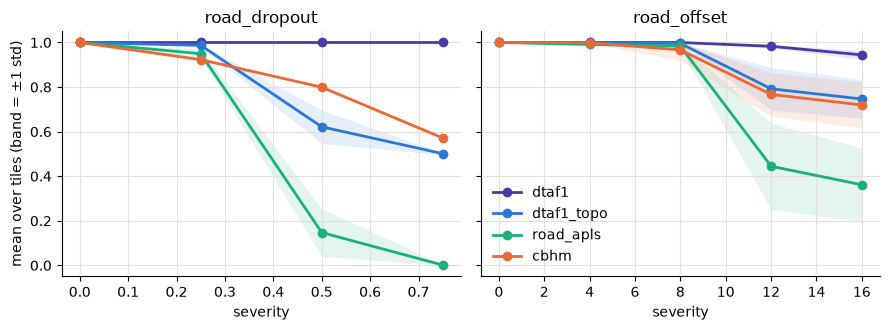

In [10]:
# Fixed metric colors (dataviz reference palette, CVD-validated); one subplot per family.
COLORS = {"dtaf1": "#4a3aa7", "dtaf1_topo": "#2a78d6", "road_apls": "#1baf7a", "cbhm": "#eb6834"}
fams = ["road_dropout", "road_offset"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, fam in zip(axes, fams):
    st = results[results.perturbation == fam].groupby("severity")[list(COLORS)].agg(["mean", "std"])
    for m, c in COLORS.items():
        mu, sd = st[(m, "mean")], st[(m, "std")]
        ax.plot(mu.index, mu.values, marker="o", color=c, lw=2, label=m)
        ax.fill_between(mu.index, (mu - sd).clip(lower=0), (mu + sd).clip(upper=1),
                        color=c, alpha=0.12, lw=0)
    ax.set_title(fam)
    ax.set_xlabel("severity")
    ax.set_ylim(-0.05, 1.05)
    ax.grid(True, color="#e1e0d9", lw=0.8)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
axes[0].set_ylabel("mean over tiles (band = ±1 std)")
axes[1].legend(frameon=False, loc="lower left")
fig.tight_layout()
plt.show()

## Findings

From the outputs above (50 tiles: 25 Vegas, 25 Khartoum; sample rebuilt with the exact building-tile
index, so it is a different and larger draw than the 24 tiles of `real_data_evaluation.ipynb`).

**1. `dtaf1_topo` closes DTAF1's road-breakage blind spot on real data.** At 25/50/75% road
dropout, `dtaf1` and `dtaf1_weighted` stay at 1.000, while `dtaf1_topo` reads 0.987/0.622/0.501
and road APLS 0.950/0.147/0.001. Buildings are untouched by this perturbation, so 0.50 is the
floor of the two-class macro average: at 75% the road term has collapsed completely. The older
findings reproduce on this larger sample: at 75% dropout `cbhm` 0.572 and `cldice_mean` 0.400
(previously ~0.57 and ~0.40).

**2. Under road offset `dtaf1_topo` degrades gracefully up to the 10 px snap radius** (0.998 at
4 px, 0.996 at 8 px) and then drops (0.792 at 12 px, 0.747 at 16 px; `dtaf1` 0.983/0.944).

**3. Sparse-class collapse, re-measured on corrected building labels.** `Khartoum_img371` (road
0.06% of the tile, 1,052 road px against 1,529 building px): a 12 px offset gives `cbhm` 0.000,
`dtaf1` 0.934, `cbhm_soft` 0.592 (exactly the building pixel share). The earlier report of
0.285, explained by the road outnumbering the building, came from building labels that the old
approximate tile matching had partly missed. `dtaf1_topo` also falls to 0.500 there (road APLS
0): once the shift passes the snap radius no control point on the short road matches, the APLS
failure mode on sparse roads. `Khartoum_img333` (buildings 5.6x road): `cbhm` 0.45-0.52 becomes
`cbhm_soft` 0.89-0.90 at 8-16 px.

**4. The exact-zero collapse is rare.** No tile in the 50-tile sample reaches `cbhm` = 0 under any
offset (minimum 0.416). Aggregates: offset 16 px `cbhm` 0.720 -> `cbhm_soft` 0.787; dropout 75%
0.572 -> 0.707.
